# The coherence and its uncertainty

This notebook explains how Stingray estimates the **coherence** between two energy bands, and
how it calculates its **error bars**. It then shows, with simulations, that these error bars
can be trusted: from weak to strong signals, from no coherence to full coherence, and in a full
analysis of simulated event lists done as in the *Spectral Timing* tutorial.

The last part introduces a variant that crosses **two detectors** observing the same source
(e.g. the two NuSTAR modules). This variant does not need to know the Poisson noise level,
which is useful when instrumental effects like dead time distort it.

The notebook needs a version of Stingray where `intrinsic_coherence` accepts
`return_interval` and `cross_detector_coherence` exists. The main functions are written out
in the notebook, and checked against Stingray, so that every step can be read.

**Contents**

1. What the coherence measures
2. Poisson noise and the bias of the coherence
3. Error bars, and how to check them: *coverage*
4. A better interval
5. Proof that it works, in a toy model and in a full analysis
6. Two detectors: no noise level to subtract
7. Summary and recipe

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from astropy.modeling import models
from scipy import optimize

from stingray import AveragedCrossspectrum, EventList, Lightcurve
from stingray.crossspectrum import cross_detector_spectral_matrix
from stingray.deadtime.model import non_paralyzable_dead_time_model
from stingray.fourier import (
    cross_detector_coherence,
    intrinsic_coherence,
    poisson_level,
)
from stingray.simulator.simulator import Simulator
from stingray.utils import rebin_data_log

plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})

# Random numbers for the Fourier amplitudes we simulate directly (sections 1-5)
rng = np.random.default_rng(20261111)
# Stingray's Simulator and EventList.simulate_times draw from NumPy's global generator
np.random.seed(20261111)

## 1. What the coherence measures

Take the light curves of the same source in two energy bands, "soft" (band 1) and "hard"
(band 2). Split them into $m$ segments of equal length, and calculate the Fourier transform of
each segment. At a given frequency $f$, each segment gives a complex number for each band: the
**Fourier amplitudes** $A_1$ and $A_2$. Their modulus tells how strong the variability at
that frequency is, and their argument (the angle in the complex plane) tells when the
oscillation peaks.

From the amplitudes we build:

* the **power spectra** $P_1 = |A_1|^2$ and $P_2 = |A_2|^2$, which measure the variability
  in each band;
* the **cross spectrum** $C = A_1^* A_2$ (the star means complex conjugate). Its argument is
  the **phase lag** between the bands: the difference of their angles.

The **coherence** is

$$
\gamma^2 = \frac{|\langle C \rangle|^2}{\langle P_1\rangle \langle P_2 \rangle},
$$

where $\langle \cdot \rangle$ is the average over the $m$ segments. It tells how much of the
variability of one band can be predicted from the other with a *linear filter*: a time
delay, a smoothing, a change of amplitude. If the hard band is just a delayed copy of the
soft band, $\gamma^2 = 1$. If the two bands vary independently, $\gamma^2 = 0$.

### What the spectra look like

Before going to single frequencies, let us look at a whole spectrum. We simulate a source with
three independent components of variability, each with a Lorentzian power spectrum centred at
zero frequency (a common shape for the noise of accreting compact objects):

* component **A**, 20% rms, half width 1 Hz, is seen by **both** bands (band 2 sees it 2 ms
  later). It makes the bands coherent;
* component **B**, 10% rms, half width 10 Hz, is seen only by band 1;
* component **C**, 15% rms, half width 30 Hz, is seen only by band 2.

So the coherence is close to 1 at low frequencies, where A dominates, and drops at high
frequencies, where B and C take over. We generate the light curves of the components with
Stingray's `Simulator`, and the photons of each band, at 100 counts/s, with
`EventList.simulate_times`. We use the same source in section 5 to test the whole analysis.

In [2]:
# Time resolution (s), segment length (s), number of segments in one observation
dt_full, segment_full, n_seg_full = 1 / 512, 32.0, 64
T_full = segment_full * n_seg_full  # length of one observation (s)
n_bins_full = int(T_full / dt_full)  # number of time bins in one observation
rates_full = (100.0, 100.0)  # mean count rates of band 1 and band 2 (counts/s)
# name: (fractional rms, half width at half maximum in Hz)
components = {"A": (0.20, 1.0), "B": (0.10, 10.0), "C": (0.15, 30.0)}
lag_bins = 1  # band 2 sees component A one time bin (about 2 ms) later than band 1


def lorentzian(hwhm):
    # Zero-centred Lorentzian, as an astropy model (the Simulator accepts astropy models)
    return models.Lorentz1D(amplitude=1, x_0=0, fwhm=2 * hwhm)


def simulate_component(rms, hwhm, dt, n_bins):
    # Zero-mean light curve of one component, in units of the mean count rate, from Stingray's
    # Simulator (Timmer & Koenig 1995 method). With mean=0, `rms` is the standard deviation.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # the Simulator warns that a mean of zero is unphysical
        sim = Simulator(dt, n_bins, mean=0, rms=rms)
        return sim.simulate(lorentzian(hwhm)).counts


def events_from_rate(rate, dt, energy=None):
    # Photon arrival times from a count-rate curve (counts/s), with Stingray's simulate_times.
    # The rate is constant inside each time bin of length dt. A negative rate (possible with a
    # Gaussian light curve of large rms) is set to zero; we print how often this happens.
    times = np.arange(rate.size) * dt + dt / 2
    expected_counts = np.clip(rate, 0, None) * dt
    lc = Lightcurve(times, expected_counts, dt=dt, gti=[[0, rate.size * dt]], skip_checks=True)
    events = EventList()
    events.simulate_times(lc)  # draws the Poisson number of photons and their times
    if energy is not None:  # an energy label, used below to separate the bands again
        events.energy = np.full(events.time.size, float(energy))
    return events


def simulate_observation():
    # One observation of the two bands, as two event lists
    a, b, c = (simulate_component(*components[name], dt_full, n_bins_full) for name in "ABC")
    rate1 = rates_full[0] * (1 + a + b)
    rate2 = rates_full[1] * (1 + np.roll(a, lag_bins) + c)  # np.roll delays A by lag_bins
    return events_from_rate(rate1, dt_full), events_from_rate(rate2, dt_full)


def model_spectra(freq):
    # Expected power spectra of the two bands and their cross spectrum, in fractional rms
    # normalization. The Simulator scales each light curve to the requested rms, so each
    # power spectrum is rms^2 * shape, with the shape normalized to unit integral over the
    # frequencies of the simulation.
    sim_freq = np.fft.rfftfreq(n_bins_full, dt_full)[1:]
    power = {}
    for name, (rms, hwhm) in components.items():
        shape = lorentzian(hwhm)
        power[name] = rms**2 * shape(freq) / (np.sum(shape(sim_freq)) / T_full)
    delay = np.exp(-2j * np.pi * freq * lag_bins * dt_full)  # phase of the 1-bin delay of A
    return power["A"] + power["B"], power["A"] + power["C"], power["A"] * delay

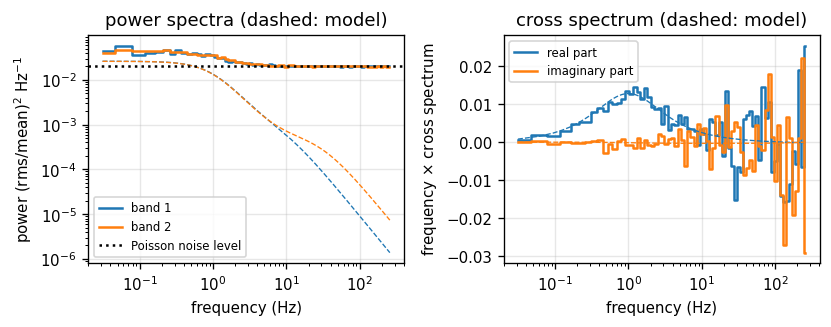

In [3]:
ev1, ev2 = simulate_observation()
# The cross spectrum and the two power spectra (cs.pds1, cs.pds2), averaged over the segments
example_cs = AveragedCrossspectrum.from_events(
    ev1, ev2, segment_size=segment_full, dt=dt_full, norm="frac", silent=True
)
example_reb = example_cs.rebin_log(0.1)  # average more frequency bins at higher frequencies
model_p1, model_p2, model_cross = model_spectra(example_cs.freq)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(7, 2.8))
for pds, model, label, color in (
    (example_reb.pds1, model_p1, "band 1", "C0"),
    (example_reb.pds2, model_p2, "band 2", "C1"),
):
    ax0.plot(pds.freq, pds.power, drawstyle="steps-mid", color=color, label=label)
    ax0.plot(example_cs.freq, model, color=color, ls="--", lw=0.8)
ax0.axhline(poisson_level("frac", meanrate=ev1.time.size / T_full), color="k", ls=":",
            label="Poisson noise level")
ax0.set(xscale="log", yscale="log", xlabel="frequency (Hz)",
        ylabel=r"power (rms/mean)$^2$ Hz$^{-1}$", title="power spectra (dashed: model)")
ax0.legend(fontsize=7)

f = example_reb.freq
ax1.plot(f, f * example_reb.power.real, drawstyle="steps-mid", label="real part")
ax1.plot(f, f * example_reb.power.imag, drawstyle="steps-mid", label="imaginary part")
ax1.plot(example_cs.freq, example_cs.freq * model_cross.real, "C0--", lw=0.8)
ax1.plot(example_cs.freq, example_cs.freq * model_cross.imag, "C1--", lw=0.8)
ax1.set(xscale="log", xlabel="frequency (Hz)", ylabel=r"frequency $\times$ cross spectrum",
        title="cross spectrum (dashed: model)")
ax1.legend(fontsize=7)
fig.tight_layout()
plt.show()

The power spectra follow the model plus a flat Poisson noise level. Above about 10 Hz, the noise
dominates. The cross spectrum has no noise level: the Poisson noise of the two bands is
independent, so it averages to zero. Its real part follows component A, and its small imaginary
part comes from the 2 ms delay.

Each frequency bin of these spectra is a separate measurement. In sections 1 to 5 we study what
happens in **one** frequency bin, simulating its Fourier amplitudes directly. In section 5 we
come back to the whole spectrum.

Why the average over segments? In a single segment $|C|^2 = |A_1|^2 |A_2|^2 = P_1 P_2$, so the
ratio is always exactly 1, whatever the bands do. The information is in how the phase lag
changes from segment to segment. If it is always the same, the cross spectra of all segments
point in the same direction and their average is long. If it changes randomly, they point in
random directions, and their average shrinks.

### A toy model

To see this, we build a hard band from two parts: a copy of the soft band, with a phase lag,
carrying a fraction $c$ of the hard-band variability, and an unrelated signal carrying the rest:

$$
A_2 = \sqrt{c}\, A_1\, e^{-i\phi} + \sqrt{1 - c}\, A_{\rm other}.
$$

The coherence of this model is exactly $c$. For noise-like variability, the Fourier amplitudes
at a given frequency behave like random complex numbers, whose real and imaginary parts follow a
Gaussian distribution. So we can simulate the amplitudes directly, without simulating light
curves. The function below does this, adding independent Poisson noise of power $N$ to each band
(more on noise in section 2).

In [4]:
def complex_gaussian(size):
    # Random complex numbers with Gaussian real and imaginary parts, and <|z|^2> = 1
    return (rng.normal(size=size) + 1j * rng.normal(size=size)) / np.sqrt(2)


def simulate_amplitudes(signal_power, coherence, m, n_sim, noise_power=1.0, phase=0.5):
    # Fourier amplitudes of two bands at one frequency: m segments, repeated n_sim times.
    # The result has shape (n_sim, m): one row per simulated observation.
    soft = complex_gaussian((n_sim, m))  # source variability in band 1
    other = complex_gaussian((n_sim, m))  # variability seen only by band 2
    # Band 2: a delayed copy of band 1 (fraction `coherence` of its power) plus the rest
    hard = np.sqrt(coherence) * soft * np.exp(-1j * phase) + np.sqrt(1 - coherence) * other
    # Both bands have the same source power; add independent Poisson noise to each
    a1 = np.sqrt(signal_power) * soft + np.sqrt(noise_power) * complex_gaussian((n_sim, m))
    a2 = np.sqrt(signal_power) * hard + np.sqrt(noise_power) * complex_gaussian((n_sim, m))
    return a1, a2


def averaged_spectra(a1, a2):
    # Cross spectrum and power spectra, averaged over the segments (last axis)
    cross = np.mean(np.conj(a1) * a2, axis=-1)
    return cross, np.mean(np.abs(a1) ** 2, axis=-1), np.mean(np.abs(a2) ** 2, axis=-1)

Here are the cross spectra of 30 segments of one simulated observation, without noise, for a
high and a low coherence. Each grey line is the cross spectrum of one segment, the red arrow is
their average:

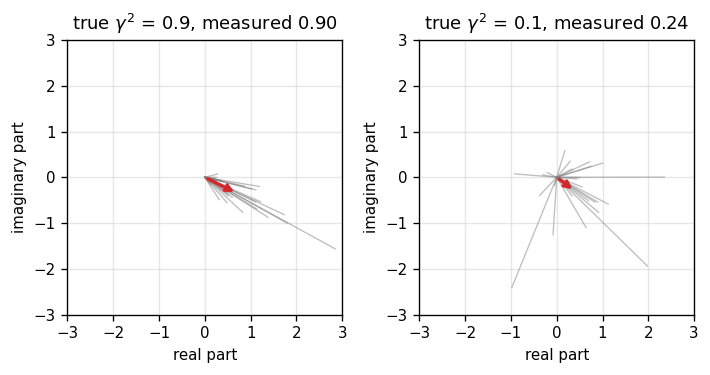

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, c in zip(axes, (0.9, 0.1)):
    a1, a2 = simulate_amplitudes(1.0, c, m=30, n_sim=1, noise_power=0)
    each_segment = (np.conj(a1) * a2)[0]  # one cross spectrum per segment
    for z in each_segment:
        ax.plot([0, z.real], [0, z.imag], color="grey", alpha=0.5, lw=0.8)
    mean = each_segment.mean()
    ax.annotate("", xy=(mean.real, mean.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="C3", lw=2))
    # coherence of this observation: |<C>|^2 / (<P1> <P2>)
    gamma2 = np.abs(mean) ** 2 / (np.mean(np.abs(a1) ** 2) * np.mean(np.abs(a2) ** 2))
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", xlabel="real part", ylabel="imaginary part",
           title=rf"true $\gamma^2$ = {c}, measured {gamma2:.2f}")
fig.tight_layout()
plt.show()

With high coherence, the segments agree on the direction (the phase lag of 0.5 radians) and the
average is long. With low coherence they point everywhere, and the average is short, but not
zero: the average of 30 random vectors is never exactly zero. This is where the bias discussed
below comes from.

Still without noise, let us measure the coherence of the toy model with $c = 0.6$ for an
increasing number of segments. Each point is the average over 2000 simulations, and the shaded
band contains the central 68% of them.

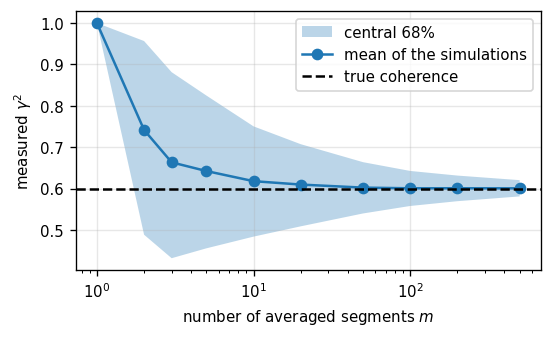

In [6]:
true_c = 0.6
ms = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200, 500])
raw = []
for m in ms:
    # 2000 observations of m segments each, without noise
    cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, true_c, m, 2000, noise_power=0))
    raw.append(np.abs(cross) ** 2 / (p1 * p2))  # coherence of each observation
raw = np.array(raw)

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.fill_between(ms, *np.percentile(raw, [16, 84], axis=1), alpha=0.3, label="central 68%")
ax.plot(ms, raw.mean(axis=1), "o-", label="mean of the simulations")
ax.axhline(true_c, color="k", ls="--", label="true coherence")
ax.set(xscale="log", xlabel="number of averaged segments $m$", ylabel=r"measured $\gamma^2$")
ax.legend()
plt.show()

With one segment the coherence is always 1. With more segments it approaches the true value
from above, and the scatter shrinks. The measured coherence is **biased**: on average it is
larger than the true value, by an amount that decreases as $1/m$. The next section explains
where this comes from.

## 2. Poisson noise and the bias of the coherence

Real light curves contain Poisson noise (counting noise), which is independent in the two
bands. It adds a constant **noise level** $N$ to each power spectrum, as in the figure of
section 1, and it makes the bands look less coherent than the source is. Vaughan & Nowak (1997,
ApJ 474, L43; "VN97" below) proposed to correct for it. Stingray's `intrinsic_coherence` uses an
improved version of their **intrinsic coherence**:

$$
\gamma^2 = \frac{|\langle C \rangle|^2 - b^2}{S_1 S_2 - c^2}.
$$

The terms are:

* $S_1 = \langle P_1\rangle - N_1$ and $S_2 = \langle P_2\rangle - N_2$: the powers of the
  source alone, after subtracting the noise levels.
* $b^2 = \langle P_1\rangle \langle P_2\rangle / m$: the **bias** of the numerator.
* $c^2 = \max(|\langle C \rangle|^2 - b^2, 0) / m$: a smaller correction of the denominator.

In code, this is all there is to the estimate. We check that it gives the same numbers as
Stingray's `intrinsic_coherence`:

In [7]:
def my_intrinsic_coherence(cross, p1, p2, n1, n2, m):
    # Intrinsic coherence, as calculated by stingray.fourier.intrinsic_coherence
    s1, s2 = p1 - n1, p2 - n2  # power of the source alone, in each band
    csq = np.abs(cross) ** 2  # squared modulus of the averaged cross spectrum
    b2 = p1 * p2 / m  # its bias: on average, csq is larger than the true value by b2
    c2 = np.clip(csq - b2, 0, s1 * s2) / m  # bias of the denominator
    gamma2 = (csq - b2) / (s1 * s2 - c2)
    # undefined if a power is not above its noise level
    return np.where((s1 > 0) & (s2 > 0), gamma2, np.nan)


# Compare with Stingray on 1000 simulated observations
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.5, 20, 1000))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # Stingray warns about the NaN values
    difference = my_intrinsic_coherence(cross, p1, p2, 1.0, 1.0, 20) - intrinsic_coherence(
        cross, p1, p2, 1.0, 1.0, 20
    )
print(f"Largest difference from Stingray: {np.nanmax(np.abs(difference)):.1e}")

Largest difference from Stingray: 4.4e-15


### Where $b^2$ comes from

$\langle C \rangle$ is an average of random complex numbers, so it scatters around its true
value $C_{\rm true}$. Write $\langle C \rangle = C_{\rm true} + \delta$, with $\delta$ the
random error. Then

$$
|\langle C \rangle|^2 = |C_{\rm true}|^2 + 2\,{\rm Re}(C_{\rm true}^*\delta) + |\delta|^2.
$$

The middle term averages to zero, but $|\delta|^2$ is never negative: on average,
$|\langle C \rangle|^2$ is larger than $|C_{\rm true}|^2$ by the **variance** of
$\langle C \rangle$ (the average of $|\delta|^2$). This is the same reason why the average of
$x^2$ is larger than the square of the average of $x$. For Gaussian Fourier amplitudes this
variance is exactly $\langle P_1\rangle \langle P_2\rangle / m$. It contains the noise, but
also the part of the source variability that is *not* coherent between the bands. VN97's bias
term only contained the noise.

The cleanest way to see the bias is with no coherence at all. Then $C_{\rm true} = 0$, so
$|\langle C\rangle|^2 = |\delta|^2$, which should average to $b^2$. In fact, the squared modulus
of a complex Gaussian number follows an **exponential distribution**, whose mean is its
variance:

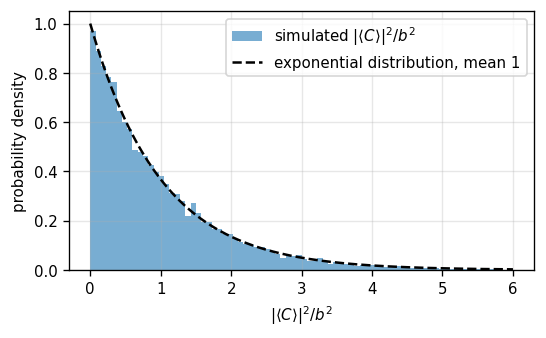

Mean of |<C>|^2 / b^2: 0.986 (expected: 1)


In [8]:
m = 50
# 20000 observations with no coherence; source power 1, noise power 1
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.0, m, 20000))
b2 = p1 * p2 / m  # expected bias of |<C>|^2
x = np.abs(cross) ** 2 / b2  # |<C>|^2 in units of its expected bias

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.hist(x, bins=80, range=(0, 6), density=True, alpha=0.6, label=r"simulated $|\langle C\rangle|^2 / b^2$")
grid = np.linspace(0, 6, 200)
ax.plot(grid, np.exp(-grid), "k--", label="exponential distribution, mean 1")
ax.set(xlabel=r"$|\langle C\rangle|^2 / b^2$", ylabel="probability density")
ax.legend()
plt.show()
print(f"Mean of |<C>|^2 / b^2: {x.mean():.3f} (expected: 1)")

### The bias, old and new

Let us compare, as a function of the true coherence, the average of three estimates:

* no bias correction at all, only the noise levels subtracted in the denominator;
* VN97's bias term, $n^2 = (\langle P_1\rangle\langle P_2\rangle - S_1 S_2)/m$, as previously
  implemented in Stingray (which also set negative values to 0);
* the new estimate.

Here the source power is 3 times the noise power in both bands, and $m = 20$. (With a weaker
source, the noise-subtracted powers in the denominator are sometimes close to zero, and averages
of the ratio become dominated by a few huge values.)

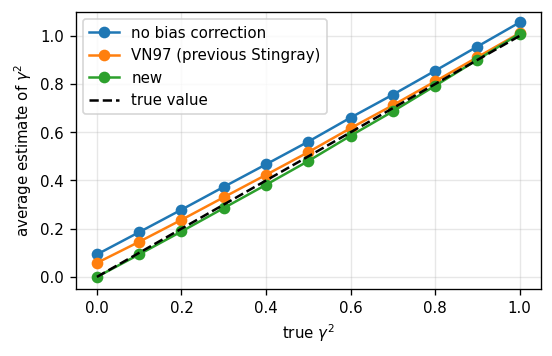

In [9]:
def vn97_old(cross, p1, p2, n1, n2, m):
    # Intrinsic coherence and its uncertainty as previously implemented in Stingray (VN97 eq. 8)
    s1, s2 = p1 - n1, p2 - n2  # noise-subtracted powers
    # the old code refused powers less than 3 sigma above the noise level
    too_low = (s1 <= 3 * n1 / np.sqrt(m)) | (s2 <= 3 * n2 / np.sqrt(m))
    nsq = 0.0 if m > 500 else (p1 * p2 - s1 * s2) / m  # VN97 bias term: noise only
    num = np.abs(cross) ** 2 - nsq
    coh = num / (s1 * s2)
    err = coh / np.sqrt(m) * np.sqrt(
        2 * nsq**2 * m / (num - nsq) ** 2
        + (n1 / s1) ** 2
        + (n2 / s2) ** 2
        + 2 * ((1 - coh) / coh**1.5) ** 2
    )
    coh = np.where(num < 0, 0.0, coh)  # negative values were set to zero...
    err = np.where(num < 0, np.nan, err)  # ...and given no error bar
    return np.where(too_low, np.nan, coh), np.where(too_low, np.nan, err)


m, signal_power = 20, 3.0
true_values = np.linspace(0, 1, 11)
means = {"no bias correction": [], "VN97 (previous Stingray)": [], "new": []}
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for c in true_values:
        # 20000 observations for each true coherence; noise power 1 in both bands
        cross, p1, p2 = averaged_spectra(*simulate_amplitudes(signal_power, c, m, 20000))
        means["no bias correction"].append(np.mean(np.abs(cross) ** 2 / ((p1 - 1) * (p2 - 1))))
        means["VN97 (previous Stingray)"].append(np.nanmean(vn97_old(cross, p1, p2, 1.0, 1.0, m)[0]))
        means["new"].append(np.nanmean(my_intrinsic_coherence(cross, p1, p2, 1.0, 1.0, m)))

fig, ax = plt.subplots(figsize=(5, 3))
for label, values in means.items():
    ax.plot(true_values, values, "o-", label=label)
ax.plot([0, 1], [0, 1], "k--", label="true value")
ax.set(xlabel=r"true $\gamma^2$", ylabel=r"average estimate of $\gamma^2$", ylim=(-0.05, 1.1))
ax.legend()
plt.show()

Without a bias correction, the estimate is far too high. VN97's correction helps but leaves
part of the bias, especially at low coherence (where the incoherent signal it leaves out is
largest). The old implementation also replaced negative values with 0, which pushes the
average up. The new estimate is on the true line at zero coherence, and within about 0.02
elsewhere. This small remaining bias comes from dividing two noisy quantities, it shrinks
like $1/m$, and it is several times smaller than the error bars (about 0.1 here).

The new estimate can be **negative**. If the bands are not coherent, the measured
$|\langle C\rangle|^2$ is sometimes smaller than its average $b^2$, as in the histogram above.
Keeping these values is what makes the average right: if we replaced them with zero, the
average would be too large. When the estimate is negative, the honest conclusion is "the
coherence is small", and the error bar (next section) says how small.

## 3. Error bars, and how to check them: *coverage*

A 1-sigma error bar (or **1-sigma interval**) should contain the true value about 68% of the
time, as for a Gaussian distribution. The fraction of times it actually does is called its
**coverage**. With simulations we know the true value, so we can measure the coverage: simulate
the same observation many times, calculate the interval each time, and count how often it
contains the truth.

* coverage of about 0.68: the error bars are right;
* coverage much lower: they are too small, and we claim more precision than we have;
* coverage much higher: they are too large, and we are throwing information away.

The previous implementation used VN97's eq. 8 for the error bar. Let us measure its coverage at
a few values of the true coherence, with source power equal to noise power and $m = 50$:

In [10]:
def coverage(lower, upper, truth):
    # Fraction of intervals that contain the truth (an undefined interval counts as a miss)
    return np.mean((lower <= truth) & (truth <= upper))


m, n_sim = 50, 4000
print("true coherence | coverage of the old error bar | fraction of undefined error bars")
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for c in (0.0, 0.1, 0.3, 0.6, 0.9):
        cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, c, m, n_sim))
        coh, err = vn97_old(cross, p1, p2, 1.0, 1.0, m)
        # the old error bar is symmetric: [coh - err, coh + err]
        print(f"{c:14.1f} | {coverage(coh - err, coh + err, c):29.2f} | {np.mean(np.isnan(err)):.2f}")

true coherence | coverage of the old error bar | fraction of undefined error bars
           0.0 |                          0.43 | 0.55
           0.1 |                          0.69 | 0.24
           0.3 |                          0.78 | 0.06
           0.6 |                          0.66 | 0.03
           0.9 |                          0.57 | 0.02


The old error bars cover the true value between 46% and 76% of the time, and at low coherence
many of them cannot be calculated at all. This is one of the *best* cases: the full map in
section 5 shows coverages from 0% to 100%. Checking VN97's derivation, we found
a few problems (listed in the Stingray documentation). Two typos make one term too small by a
factor of about $m$, a relative error is used as an absolute one, and some terms are missing.

There is also a deeper problem, which affects any error bar of the form "estimate $\pm\,\sigma$
calculated at the estimate". Near zero coherence, the scatter of the estimate depends strongly
on the true value. If the measured coherence happens to be close to zero, a formula evaluated at
the measured value gives a tiny error bar, exactly when we should be most careful.

## 4. A better interval

The idea is to turn the question around. Instead of asking "how much does the estimate scatter
around the measured value?", we ask, for every possible true value $\gamma^2_0$: **"if the truth
were $\gamma^2_0$, would our measurement be surprising?"**

1. For each candidate $\gamma^2_0$, calculate how much the estimate would scatter if
   $\gamma^2_0$ were the truth: its standard deviation $\sigma(\gamma^2_0)$.
2. Keep $\gamma^2_0$ if the measured value $\hat\gamma^2$ (the hat marks the measured value) is
   within one standard deviation of it: $|\hat\gamma^2 - \gamma^2_0| \le \sigma(\gamma^2_0)$.
3. The interval is the range of kept values.

Statisticians call this *inverting a test*: each candidate value is "tested" against the data,
and the interval collects the candidates that pass. The key difference from the usual error bar
is that $\sigma$ is calculated for each candidate, not at the noisy measured value.

### The standard deviation $\sigma(\gamma^2_0)$

For Gaussian Fourier amplitudes, all the averages and their correlations can be calculated
exactly. Calling $r_1 = N_1/S_1$ and $r_2 = N_2/S_2$ the noise-to-signal ratios of the two bands,
and $q = r_1 + r_2 + r_1 r_2$, the variance (the square of $\sigma$) is

$$
\sigma^2(\gamma^2_0) =
\underbrace{\frac{2\gamma^2_0 (1 - \gamma^2_0)(1 - \gamma^2_0 + q) + (\gamma^2_0)^2 (r_1 + r_2)^2}{m}}_{\text{first order}}
+ \underbrace{\left(\kappa\, \frac{\langle P_1\rangle\langle P_2\rangle - \gamma^2_0 S_1 S_2}{m S_1 S_2}\right)^2}_{\text{second order}}.
$$

* The **first-order** term is the usual propagation of errors from the lab courses: it
  describes how small fluctuations of the cross spectrum and of the two powers move the ratio,
  including the fact that these fluctuations are correlated. Without noise ($r_1 = r_2 = 0$) it
  gives the classic result $2\gamma^2(1-\gamma^2)^2/m$. At full coherence it reduces to
  $\sigma = (r_1 + r_2)/\sqrt{m}$: only the noise makes the coherence scatter.
* The first-order term vanishes at $\gamma^2_0 = 0$, but the estimate still scatters there:
  we saw that $|\langle C\rangle|^2$ then follows an exponential distribution. The
  **second-order** term describes this. Its numerator is the incoherent part of the variance of
  the cross spectrum, and it vanishes for a perfectly coherent signal without noise.

### Where $\kappa = 0.83$ comes from

At zero coherence, $|\langle C\rangle|^2$ follows an exponential distribution with mean $b^2$,
and the estimate subtracts $b^2$. We want the interval $\pm\sigma$ around the mean to contain 68.27%
of the distribution, as for a Gaussian. For an exponential distribution with mean 1, the
probability to fall within $1 \pm \kappa$ is $e^{-(1-\kappa)} - e^{-(1+\kappa)} = 2 e^{-1} \sinh\kappa$.
Setting it to 0.6827 gives $\kappa \approx 0.83$:

kappa = 0.829


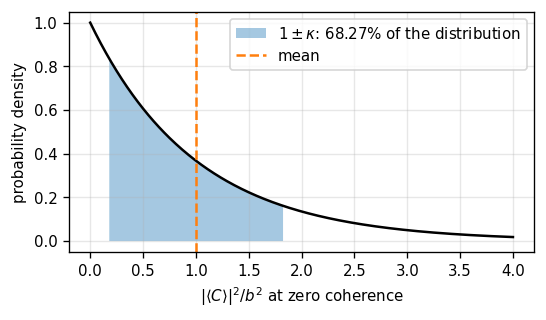

In [11]:
# Solve 2 exp(-1) sinh(kappa) = 0.6827 for kappa
kappa = optimize.brentq(lambda k: 2 * np.exp(-1) * np.sinh(k) - 0.6827, 0, 1)
print(f"kappa = {kappa:.3f}")

grid = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(grid, np.exp(-grid), "k-")
inside = (grid > 1 - kappa) & (grid < 1 + kappa)
ax.fill_between(grid[inside], np.exp(-grid[inside]), alpha=0.4, label=r"$1 \pm \kappa$: 68.27% of the distribution")
ax.axvline(1, color="C1", ls="--", label="mean")
ax.set(xlabel=r"$|\langle C\rangle|^2 / b^2$ at zero coherence", ylabel="probability density")
ax.legend()
plt.show()

### The interval in code

Here are the variance and the interval, written to be read rather than to be fast. The
interval scans a fine grid of candidate values from 0 to 2. Below zero, the standard deviation
is the one at zero, so the lower end there is simply $\hat\gamma^2 - \sigma(0)$. Stingray does the
same, but for whole arrays at once and refining the ends by bisection (halving the step until
it is tiny), which is much faster. We check that the two agree.

In [12]:
KAPPA = 0.83  # kappa from above, rounded as in Stingray


def coherence_variance(g0, p1, p2, s1, s2, m):
    # Variance of the intrinsic coherence estimate, if the true coherence were g0.
    # p1, p2: measured powers; s1, s2: noise-subtracted powers; m: number of averaged values
    r1, r2 = (p1 - s1) / s1, (p2 - s2) / s2  # noise-to-signal ratios
    q = r1 + r2 + r1 * r2
    g0 = np.clip(g0, 0, None)  # below zero, use the variance at zero
    first = (2 * g0 * (1 - g0) * (1 - g0 + q) + g0**2 * (r1 + r2) ** 2) / m
    second = (KAPPA * (p1 * p2 - g0 * s1 * s2) / (m * s1 * s2)) ** 2
    return np.clip(first, 0, None) + second


def test_inversion_interval(measured, variance, upper_limit=2.0, n_grid=20001):
    # 1-sigma interval of one measurement. `variance(g0)` is the variance of the estimate if
    # the truth were g0. Keep the candidates g0 with |measured - g0| <= sigma(g0).
    sigma0 = np.sqrt(variance(0.0))
    candidates = np.linspace(0, upper_limit, n_grid)
    kept = candidates[(measured - candidates) ** 2 <= variance(candidates)]
    if measured - sigma0 <= 0:
        lower = measured - sigma0  # negative candidates are kept down to here
    else:
        lower = kept.min()
    if kept.size == 0:  # no candidate above zero is kept: the whole interval is negative
        upper = measured + sigma0
    else:
        upper = max(kept.max(), measured)  # an upper end of 2 means: not constrained
    return lower, upper


# Compare with Stingray on 200 simulated observations, source power = noise power, m = 50
m = 50
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.3, m, 200))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    coh, lower, upper = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, m, return_interval=True)
largest = 0
for i in np.flatnonzero(~np.isnan(coh)):
    s1, s2 = p1[i] - 1.0, p2[i] - 1.0
    mine = test_inversion_interval(coh[i], lambda g0: coherence_variance(g0, p1[i], p2[i], s1, s2, m))
    largest = max(largest, abs(mine[0] - lower[i]), abs(mine[1] - upper[i]))
print(f"Largest difference from Stingray's interval ends: {largest:.1e} (grid step: {2 / 20000:.0e})")

Largest difference from Stingray's interval ends: 1.0e-04 (grid step: 1e-04)


The figure shows the construction for one measurement: source and noise power both equal to 1,
$m = 50$, and a measured coherence of 0.05.

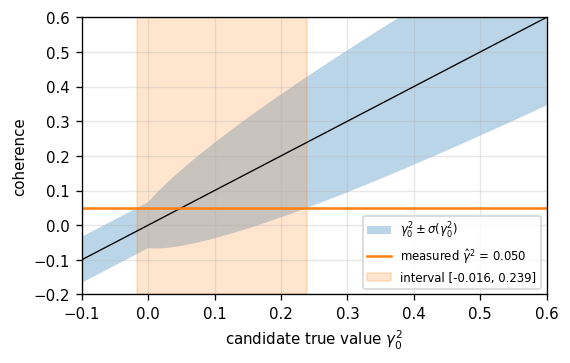

In [13]:
m, p, n = 50, 2.0, 1.0  # measured powers: source power 1 + noise level 1, in both bands
measured = 0.05
candidates = np.linspace(-0.1, 0.6, 400)
sigma = np.sqrt(coherence_variance(candidates, p, p, p - n, p - n, m))
lower, upper = test_inversion_interval(measured, lambda g0: coherence_variance(g0, p, p, p - n, p - n, m))

fig, ax = plt.subplots(figsize=(5, 3))
ax.fill_between(candidates, candidates - sigma, candidates + sigma, alpha=0.3,
                label=r"$\gamma^2_0 \pm \sigma(\gamma^2_0)$")
ax.plot(candidates, candidates, "k-", lw=0.8)
ax.axhline(measured, color="C1", label=rf"measured $\hat\gamma^2$ = {measured:.3f}")
ax.axvspan(lower, upper, color="C1", alpha=0.2, label=f"interval [{lower:.3f}, {upper:.3f}]")
ax.set(xlabel=r"candidate true value $\gamma^2_0$", ylabel="coherence", xlim=(-0.1, 0.6), ylim=(-0.2, 0.6))
ax.legend(loc="lower right", fontsize=7)
plt.show()

The interval contains the candidates for which the horizontal line (the measurement) lies inside
the shaded band. It is **asymmetric**: it extends further above the measured value than below,
because the scatter grows with the coherence near zero. It also includes slightly negative
values: below zero, the scatter is the one at zero.

### Values outside [0, 1]

Like the estimate, the interval is not restricted to the range 0 to 1. An interval entirely
below zero means that the cross spectrum is weaker than expected from noise alone: the data are
consistent with no coherence, and a bit unlucky. Restricting the interval to [0, 1] would make it
shrink to the single point [0, 0] in such cases, falsely suggesting a perfect measurement. The
candidate values are searched up to 2: an upper end of 2 means that the data cannot constrain
the coherence from above.

### Using it

`intrinsic_coherence` returns the interval with `return_interval=True`, and half its width with
`return_uncertainty=True`, which is convenient for plots with symmetric error bars:

In [14]:
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.3, 50, 5))  # 5 observations
coh, lower, upper = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, 50, return_interval=True)
coh, err = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, 50, return_uncertainty=True)
for values in zip(coh, lower, upper, err):
    print("coherence {:6.3f}, interval [{:6.3f}, {:6.3f}], half width {:.3f}".format(*values))

coherence  0.223, interval [ 0.088,  0.468], half width 0.190
coherence  0.108, interval [ 0.011,  0.372], half width 0.181
coherence  0.751, interval [ 0.512,  1.036], half width 0.262
coherence  0.195, interval [ 0.083,  0.386], half width 0.151
coherence  0.649, interval [ 0.418,  0.935], half width 0.259


## 5. Proof that it works

### In the toy model

We now measure the coverage of the old error bars and of the new interval on a grid:

* source-to-noise power ratio $S/N$ from 0.3 (the source is weaker than the noise in each
  frequency bin) to 10;
* true coherence from 0 to 1;
* $m$ = 10, 50 and 300 averaged segments (or segments times frequency bins).

Each square shows the coverage measured over 2000 simulations; its statistical uncertainty is
about 0.01. White is perfect (0.68), red means error bars that are too small, blue too large.
As before, an old error bar that cannot be calculated counts as a miss; for the new interval,
we skip the (rarer) cases where the estimate itself is undefined, and count them separately.
Here we use Stingray's `intrinsic_coherence`, which is faster than our readable version.

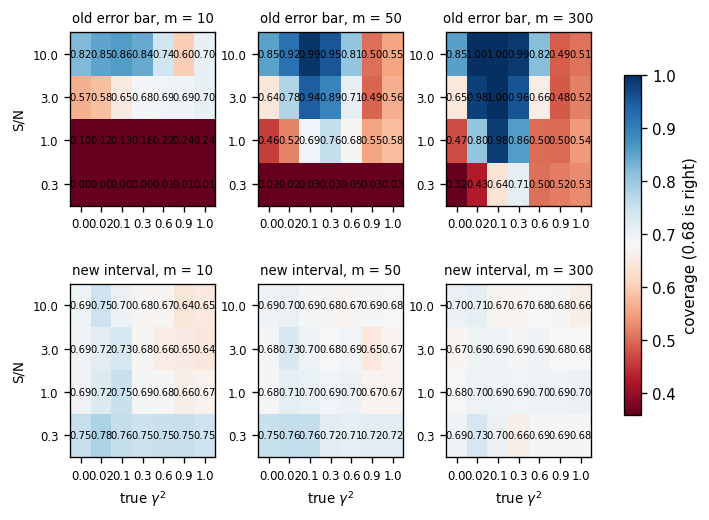

In [15]:
snrs = [0.3, 1.0, 3.0, 10.0]
cohs = [0.0, 0.02, 0.1, 0.3, 0.6, 0.9, 1.0]
segments = [10, 50, 300]
n_sim = 2000

cov_old = np.zeros((len(segments), len(snrs), len(cohs)))
cov_new = np.zeros_like(cov_old)
undefined_new = np.zeros_like(cov_old)
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for i, m in enumerate(segments):
        for j, snr in enumerate(snrs):
            for k, c in enumerate(cohs):
                # n_sim observations; source power snr, noise power 1
                cross, p1, p2 = averaged_spectra(*simulate_amplitudes(snr, c, m, n_sim))
                coh, err = vn97_old(cross, p1, p2, 1.0, 1.0, m)
                cov_old[i, j, k] = coverage(coh - err, coh + err, c)
                _, lower, upper = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, m, return_interval=True)
                defined = ~np.isnan(lower)  # NaN where a power is not above the noise level
                undefined_new[i, j, k] = 1 - defined.mean()
                cov_new[i, j, k] = coverage(lower[defined], upper[defined], c)


def coverage_maps(maps, titles, ylabels, xlabels, xticks, yticks):
    # One coverage map per panel: rows of `maps` are figure rows, with a title each
    fig, axes = plt.subplots(len(maps), len(maps[0]), figsize=(7, 2.3 * len(maps)), squeeze=False)
    for row, (row_maps, row_title) in enumerate(zip(maps, titles)):
        for col, cov in enumerate(row_maps):
            ax = axes[row, col]
            im = ax.imshow(cov, cmap="RdBu", vmin=0.36, vmax=1.0, origin="lower", aspect="auto")
            for (y, x), value in np.ndenumerate(cov):
                ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=6)
            ax.set_xticks(range(len(xticks)), xticks, fontsize=7)
            ax.set_yticks(range(len(yticks)), yticks, fontsize=7)
            ax.set_title(f"{row_title}, {xlabels[col]}", fontsize=8)
            ax.grid(False)
        axes[row, 0].set_ylabel(ylabels, fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel(r"true $\gamma^2$", fontsize=8)
    fig.subplots_adjust(hspace=0.45, wspace=0.3)
    fig.colorbar(im, ax=axes, label="coverage (0.68 is right)", shrink=0.8)
    plt.show()


coverage_maps(
    [list(cov_old), list(cov_new)],
    ["old error bar", "new interval"],
    "S/N",
    [f"m = {m}" for m in segments],
    cohs,
    snrs,
)

The old error bars range from always missing to always containing the true value, depending on
the case. When the source is weaker than the noise, they can almost never be calculated. The
new interval stays close to 0.68 everywhere. It is a bit conservative (coverage up to about
0.78) only when the source is much weaker than the noise and few segments are averaged, where
the coherence can hardly be measured. In those cases the estimate is also often undefined,
because a measured power falls below the noise level:

In [16]:
print("Fraction of undefined estimates (a power not above its noise level), S/N = 0.3:")
for i, m in enumerate(segments):
    print(f"  m = {m:3d}: {undefined_new[i, 0].mean():.2f}")
print(f"Coverage of the new interval: {cov_new.min():.2f} - {cov_new.max():.2f}, "
      f"mean distance from 0.68: {np.mean(np.abs(cov_new - 0.68)):.3f}")

Fraction of undefined estimates (a power not above its noise level), S/N = 0.3:
  m =  10: 0.43
  m =  50: 0.08
  m = 300: 0.00
Coverage of the new interval: 0.64 - 0.78, mean distance from 0.68: 0.024


### In a full analysis

The toy model simulates one frequency bin with exactly Gaussian amplitudes. A real analysis
starts from event lists, goes through Stingray's Fourier machinery, and averages neighbouring
frequency bins of different widths. Let us repeat, on the source of section 1, the analysis of
the *Spectral Timing* tutorial: `AveragedCrossspectrum.from_events`, logarithmic rebinning with
`rebin_log`, and the `intrinsic_coherence` method, now with `return_interval=True`. Its noise
levels are the standard Poisson ones, which are right here because there is no dead time.

The true coherence in each rebinned frequency bin is calculated from the model spectra of
section 1, averaged over the same frequencies as the data:
$|\langle C_{\rm model}\rangle|^2 / (\langle P_{1,\rm model}\rangle \langle P_{2,\rm model}\rangle)$.
This includes the small loss of coherence due to the phase lag changing across a wide bin.

First, the observation simulated in section 1 (64 segments of 32 s):

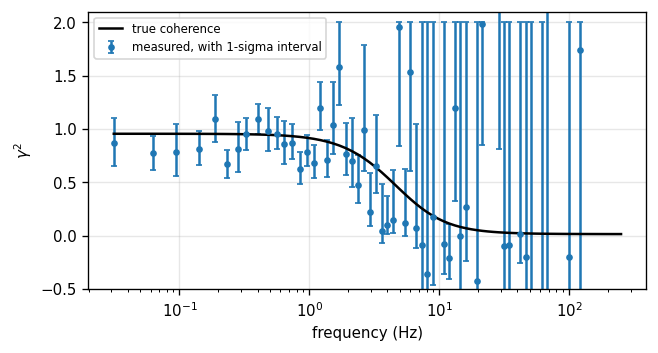

In [17]:
f_rebin = 0.1  # each rebinned bin is 10% wider than the previous one


def binned_truth(freq):
    # True coherence in the bins of rebin_log, from the model spectra averaged in each bin
    p1, p2, cross = model_spectra(freq)
    df = freq[1] - freq[0]
    binned = [rebin_data_log(freq, y, f_rebin, dx=df)[1] for y in (cross, p1, p2)]
    return np.abs(binned[0]) ** 2 / (binned[1] * binned[2])


true_full = binned_truth(example_cs.freq)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # warnings about few segments and undefined values
    coh, lower, upper = example_reb.intrinsic_coherence(return_interval=True)

fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(example_reb.freq, coh, yerr=[coh - lower, upper - coh], fmt="o", ms=3, capsize=2,
            label="measured, with 1-sigma interval")
ax.plot(example_reb.freq, true_full, "k-", label="true coherence")
ax.set(xscale="log", xlabel="frequency (Hz)", ylabel=r"$\gamma^2$", ylim=(-0.5, 2.1))
ax.legend(fontsize=7)
plt.show()

At low frequencies, where the source is stronger than the noise, the intervals are narrow and
follow the true coherence. Above about 5 Hz the source is much weaker than the noise and the
intervals become wide, often reaching the search limit of 2 (not constrained). Some estimates
are missing: they are undefined, because a measured power fell below the noise level.

Now the coverage. We repeat the same analysis on 150 independent observations (this takes
about two minutes) and count, in each frequency bin, how often the interval contains the true
coherence.

In [18]:
n_obs = 150
full_results = []  # (coherence, lower, upper) of each observation
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _ in range(n_obs):
        ev1, ev2 = simulate_observation()
        cs = AveragedCrossspectrum.from_events(
            ev1, ev2, segment_size=segment_full, dt=dt_full, norm="frac", silent=True
        )
        full_results.append(cs.rebin_log(f_rebin).intrinsic_coherence(return_interval=True))
coh, lower, upper = np.array(full_results).transpose(1, 0, 2)  # each: (n_obs, n_freq)

defined = ~np.isnan(lower)
inside = (lower <= true_full) & (true_full <= upper)
# coverage in each bin, among the observations where the estimate is defined
cov_full = np.array([inside[defined[:, j], j].mean() for j in range(true_full.size)])

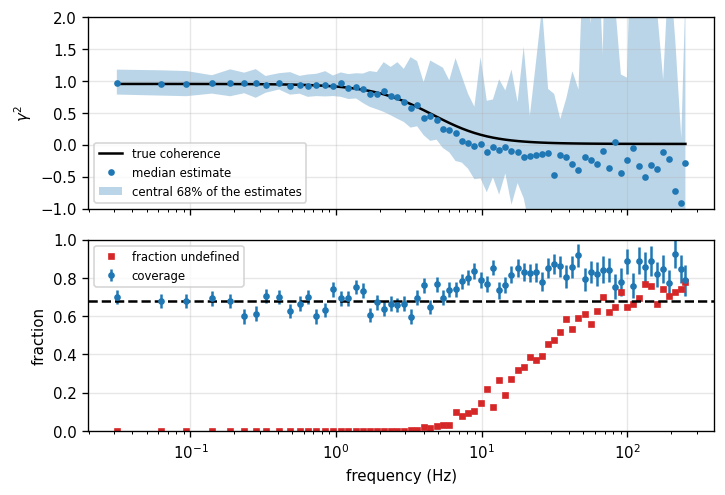

Below 5 Hz: coverage 0.60 - 0.77, average 0.676
Above 5 Hz: coverage 0.70 - 0.93, undefined 0.03 - 0.78 of the time


In [19]:
freq = example_reb.freq
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(6, 4.2), sharex=True)
ax0.plot(freq, true_full, "k-", label="true coherence")
ax0.plot(freq, np.nanmedian(coh, axis=0), "o", ms=3, label="median estimate")
ax0.fill_between(freq, *np.nanpercentile(coh, [16, 84], axis=0), alpha=0.3,
                 label="central 68% of the estimates")
ax0.set(ylabel=r"$\gamma^2$", ylim=(-1, 2))
ax0.legend(fontsize=7)

err = np.sqrt(0.68 * 0.32 / defined.sum(axis=0))  # statistical uncertainty of the coverage
ax1.errorbar(freq, cov_full, yerr=err, fmt="o", ms=3, label="coverage")
ax1.plot(freq, 1 - defined.mean(axis=0), "s", ms=3, color="C3", label="fraction undefined")
ax1.axhline(0.68, color="k", ls="--")
ax1.set(xscale="log", xlabel="frequency (Hz)", ylabel="fraction", ylim=(0, 1))
ax1.legend(fontsize=7)
fig.tight_layout()
plt.show()

well_measured = freq < 5
print(f"Below 5 Hz: coverage {cov_full[well_measured].min():.2f} - {cov_full[well_measured].max():.2f}, "
      f"average {cov_full[well_measured].mean():.3f}")
print(f"Above 5 Hz: coverage {cov_full[~well_measured].min():.2f} - {cov_full[~well_measured].max():.2f}, "
      f"undefined {1 - defined[:, ~well_measured].mean(axis=0).max():.2f} - "
      f"{1 - defined[:, ~well_measured].mean(axis=0).min():.2f} of the time")

**How to read this.** Below about 5 Hz, where the source is at least as strong as the noise, the
coverage scatters around 0.68 (the scatter of the points is consistent with their error bars),
and the median estimate follows the true coherence. Note that this is the full analysis done as
in the *Spectral Timing* tutorial: events, `AveragedCrossspectrum.from_events`, logarithmic
rebinning, `intrinsic_coherence`. The only differences are the corrected formula and the
interval.

Above about 5 Hz the source power is between 10 and 1000 times weaker than the Poisson noise:

* many estimates are **undefined** (up to three quarters of them at the highest frequencies),
  because a measured power fell below the noise level. An undefined estimate is not an error: it
  says that this band, in this frequency bin, contains no measurable signal;
* the **median** estimate falls below the true coherence. The coherence is a ratio of noisy
  quantities, and when the denominator is mostly noise its distribution becomes very skewed:
  most estimates are low, a few are very high. The interval is built for this skewed distribution,
  so the coverage is still fine;
* the coverage is **above** 0.68 (0.8-0.9): the intervals are wider than needed, i.e.
  conservative. They cover most of the allowed range anyway, so they correctly say that the
  coherence is not measured there.

In summary: where the coherence can be measured, the interval has the right coverage; where it
cannot, the interval says so and errs on the safe side.

## 6. Two detectors: no noise level to subtract

The intrinsic coherence needs the noise levels $N_1$ and $N_2$. For a pure Poisson process they
are known (e.g. 2 in Leahy normalization), but instrumental effects can change them. A common one
is **dead time**: after recording a photon, a detector is "blind" for a short time (2.5 ms for
NuSTAR). This lowers the noise level, and also changes its shape with frequency in a way that
depends on the count rate. Even small errors in $N$ matter a lot when the source is weaker than
the noise: if $N$ is 10 times $S$, a 5% error in $N$ is a 50% error in $S = \langle P\rangle - N$.

When two independent detectors observe the same source at the same time, such as the two NuSTAR
modules, we can avoid the noise level altogether. With $A$ and $B$ the Fourier amplitudes of the
two detectors, the **cospectrum** ${\rm Re}\langle A^* B\rangle$ contains the source variability,
which the two detectors share, but not the Poisson noise, which is independent in the two
detectors and averages out (Bachetti et al. 2015). For two energy bands we build a whole
**cross-spectral matrix** this way:

$$
S_{11} = {\rm Re}\langle A_1^* B_1\rangle, \qquad
S_{22} = {\rm Re}\langle A_2^* B_2\rangle, \qquad
S_{12} = \tfrac{1}{2}\langle A_1^* B_2 + B_1^* A_2\rangle.
$$

$S_{11}$ and $S_{22}$ replace the noise-subtracted powers, and $S_{12}$ replaces the cross
spectrum.

**Note on $S_{12}$.** There are two ways to cross band 1 with band 2 using different detectors:
band 1 of A with band 2 of B, and band 1 of B with band 2 of A. $S_{12}$ averages them.
This is **not** what `AveragedCrossspectrum` does: given two light curves, it only calculates
$\langle A_1^* B_2\rangle$. Stingray's `cross_detector_spectral_matrix` builds the average from
two `AveragedCrossspectrum` objects, one per pairing. Averaging the two pairings is only
worthwhile, and the formulas below are only right, if the two pairings are not correlated in
some way we did not account for. We check this at the end of this section.

The coherence is then

$$
\gamma^2 = \frac{|S_{12}|^2 - b^2}{S_{11} S_{22} - c^2}, \qquad
b^2 = \frac{p_{A1} p_{B2} + p_{B1} p_{A2} + 2 S_{11} S_{22}}{4m}, \qquad
c^2 = \frac{\max(|S_{12}|^2 - b^2, 0)}{m},
$$

where $p_{A1} = \langle|A_1|^2\rangle$ etc. are the ordinary power spectra of each detector in
each band, *including* their noise, whatever its level: they are only needed to calculate the
bias $b^2$. The bias has the same origin as before: it is the variance of $S_{12}$, i.e. the
average of the variances of the two pairings, $p_{A1} p_{B2}/m$ and $p_{B1} p_{A2}/m$, plus twice
their covariance, $S_{11} S_{22}/m$, all divided by 4.

The interval is built in the same way as before. For the variance, we use a general recipe: for
Gaussian Fourier amplitudes, the scatter of anything built from averaged products of the four
amplitudes $(A_1, B_1, A_2, B_2)$ is fixed by the true values of all those averaged products
(Isserlis' theorem: an average of four Gaussian amplitudes is a sum of products of averages of
two). Besides $S_{11}$, $S_{22}$, $S_{12}$ and the four powers, the list includes the cross
spectra of the two bands *within* each detector, $C_A = \langle A_1^* A_2\rangle$ and
$C_B = \langle B_1^* B_2\rangle$. Without instrumental effects these equal $S_{12}$, and the
general variance is the same as a closed formula with the noise-to-signal ratio of each
detector. We will see below why $C_A$ and $C_B$ matter with dead time. The function only needs
to change the coherence to the candidate value $\gamma^2_0$: if that were the truth, $S_{12}$
would be $\sqrt{\gamma^2_0 S_{11} S_{22}}$, with the measured phase. In code, with a check
against Stingray's `cross_detector_coherence`:

In [20]:
def my_cross_detector_coherence(s11, s22, s12, auto_powers, m):
    # Coherence from the cross-detector matrix, as stingray.fourier.cross_detector_coherence.
    # auto_powers: power spectra of detector A band 1, B band 1, A band 2, B band 2 (with noise)
    pa1, pb1, pa2, pb2 = auto_powers
    b2 = (pa1 * pb2 + pb1 * pa2 + 2 * s11 * s22) / (4 * m)  # variance of S12
    num = np.abs(s12) ** 2 - b2
    gamma2 = num / (s11 * s22 - np.clip(num, 0, s11 * s22) / m)
    # undefined if a cospectrum is not positive (no signal measured in that band)
    return np.where((s11 > 0) & (s22 > 0), gamma2, np.nan)


def cross_detector_variance(g0, s11, s22, s12, auto_powers, m, same_detector_cross=None):
    # Variance of the estimate if the true coherence were g0: first-order error propagation
    # with all the averaged products of the four amplitudes, plus the second-order term.
    pa1, pb1, pa2, pb2 = auto_powers
    ca, cb = (s12, s12) if same_detector_cross is None else same_detector_cross
    g0 = np.clip(g0, 0, None)
    s12_g0 = np.sqrt(g0 * s11 * s22) * np.exp(1j * np.angle(s12))  # S12 if the truth were g0
    # R[i, j] = <a_i^* a_j> for the amplitudes a = (A1, B1, A2, B2). The same-detector cross
    # spectra keep their measured difference from S12 (e.g. what dead time adds).
    upper = {(0, 0): pa1, (1, 1): pb1, (2, 2): pa2, (3, 3): pb2, (0, 1): s11, (2, 3): s22,
             (0, 3): s12_g0, (1, 2): s12_g0, (0, 2): s12_g0 + ca - s12, (1, 3): s12_g0 + cb - s12}

    def R(i, j):
        return upper[(i, j)] if i <= j else np.conj(upper[(j, i)])

    # A small change d(a_i^* a_j) of each averaged product changes the coherence by
    # Re(c * d(a_i^* a_j)): these are the (i, j, c) of S11, S22 and the two terms of S12.
    c12 = np.conj(s12_g0) / (s11 * s22)
    terms = [(0, 1, -g0 / s11), (2, 3, -g0 / s22), (0, 3, c12), (1, 2, c12)]
    total = 0
    for i, j, c in terms:
        for k, l, d in terms:
            # Isserlis' theorem: covariance (with conjugate) and pseudo-covariance (without)
            # of the products a_i^* a_j and a_k^* a_l
            total = total + c * np.conj(d) * R(i, k) * R(l, j) + c * d * R(i, l) * R(k, j)
    first = total.real / (2 * m)  # variance of the real part of a complex fluctuation
    b2 = (pa1 * pb2 + pb1 * pa2 + 2 * s11 * s22) / 4
    second = (KAPPA * (b2 - g0 * s11 * s22) / (m * s11 * s22)) ** 2
    return np.clip(first, 0, None) + second


def simulate_two_detectors(signal_power, coherence, m, n_sim, noise=(1.0, 1.0, 1.0, 1.0), phase=0.5):
    # Amplitudes of bands 1 and 2 in detectors A and B; noise = (A1, B1, A2, B2) noise levels.
    # The source is the same in both detectors; the noise is independent everywhere.
    soft = complex_gaussian((n_sim, m))
    hard = np.sqrt(coherence) * soft * np.exp(-1j * phase) + np.sqrt(1 - coherence) * complex_gaussian((n_sim, m))
    signals = np.sqrt(signal_power) * np.array([soft, soft, hard, hard])
    return [s + np.sqrt(n) * complex_gaussian((n_sim, m)) for s, n in zip(signals, noise)]


def cross_matrix(a1, b1, a2, b2):
    # Averaged S11, S22, S12 (both pairings) and the four power spectra
    s11 = np.mean(np.conj(a1) * b1, axis=-1).real
    s22 = np.mean(np.conj(a2) * b2, axis=-1).real
    s12 = np.mean(np.conj(a1) * b2 + np.conj(b1) * a2, axis=-1) / 2
    return s11, s22, s12, [np.mean(np.abs(a) ** 2, axis=-1) for a in (a1, b1, a2, b2)]


def same_detector(a1, b1, a2, b2):
    # Averaged cross spectra of band 1 and band 2 within detector A and within detector B
    return np.mean(np.conj(a1) * a2, axis=-1), np.mean(np.conj(b1) * b2, axis=-1)


# Compare with Stingray on 200 simulated observations
m = 50
amplitudes = simulate_two_detectors(1.0, 0.5, m, 200)
s11, s22, s12, auto = cross_matrix(*amplitudes)
ca, cb = same_detector(*amplitudes)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    coh, lower, upper = cross_detector_coherence(s11, s22, s12, auto, m, return_interval=True,
                                                 same_detector_cross=(ca, cb))
    mine = my_cross_detector_coherence(s11, s22, s12, auto, m)
largest = 0
for i in np.flatnonzero(~np.isnan(coh)):
    auto_i = [p[i] for p in auto]
    interval = test_inversion_interval(
        coh[i], lambda g0: cross_detector_variance(g0, s11[i], s22[i], s12[i], auto_i, m, (ca[i], cb[i]))
    )
    largest = max(largest, abs(interval[0] - lower[i]), abs(interval[1] - upper[i]))
print(f"Largest difference from Stingray: estimate {np.nanmax(np.abs(mine - coh)):.1e}, "
      f"interval ends {largest:.1e}")

Largest difference from Stingray: estimate 4.4e-16, interval ends 1.0e-04


### Coverage with simulated Fourier amplitudes

As for the single-detector case, we first check the coverage with simulated Fourier amplitudes,
now for four amplitudes ($A_1$, $B_1$, $A_2$, $B_2$). The two detectors can be different: below,
detector A has a noise level 4 times lower than detector B, as if it collected 4 times more
photons.

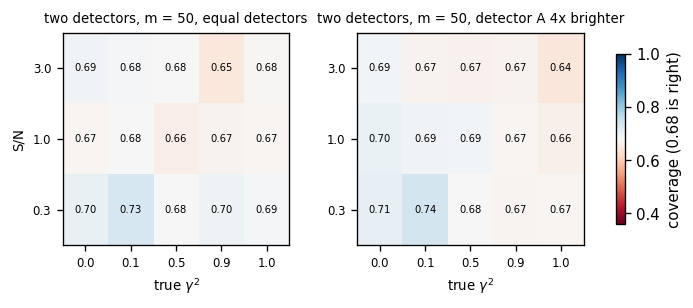

In [21]:
snrs2, cohs2, m2, n_sim = [0.3, 1.0, 3.0], [0.0, 0.1, 0.5, 0.9, 1.0], 50, 2000
# noise levels of (A1, B1, A2, B2)
setups = {"equal detectors": (1.0, 1.0, 1.0, 1.0), "detector A 4x brighter": (0.5, 2.0, 0.5, 2.0)}
cov_two = {}
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for name, noise in setups.items():
        cov = np.zeros((len(snrs2), len(cohs2)))
        for j, snr in enumerate(snrs2):
            for k, c in enumerate(cohs2):
                amplitudes = simulate_two_detectors(snr, c, m2, n_sim, noise)
                _, lower, upper = cross_detector_coherence(*cross_matrix(*amplitudes), m2, return_interval=True)
                defined = ~np.isnan(lower)  # NaN where a cospectrum is not positive
                cov[j, k] = coverage(lower[defined], upper[defined], c)
        cov_two[name] = cov

coverage_maps([list(cov_two.values())], [f"two detectors, m = {m2}"], "S/N", list(setups), cohs2, snrs2)

The coverage stays close to 0.68 for equal and different detectors. Here $S/N$ is the source
power divided by a noise level of 1; in the unequal setup detector A has noise 0.5 and detector B
noise 2.

### A dead-time experiment

Now the real test: event lists from two detectors with 2.5 ms of dead time, analysed with
Stingray's `cross_detector_spectral_matrix`. We want to check the coverage at frequencies up to
400 Hz $= 1/(2.5\,{\rm ms})$, where dead time changes the noise level the most.

The source has the same structure as in section 1, with components that extend to high
frequencies, so that there is something to measure there:

* component **A** is seen by both bands: a Lorentzian of half width 1 Hz with 15% rms, plus one
  of half width 500 Hz with 35% rms;
* components **B** (band 1 only) and **C** (band 2 only) have half width 500 Hz and 19% rms.

Each band sends 200 photons/s to each detector, so each detector receives 400 photons/s and is
dead about half of the time. This is more than in a typical NuSTAR observation, and it makes the
dead-time effects large.

How the events are made: the photons of each band come from Stingray's `Simulator` and
`EventList.simulate_times`, as in section 1. We then put the two bands of one detector in a
single event list, labelling them with an energy of 1 keV (band 1) or 5 keV (band 2), and apply
the dead time with `EventList.apply_deadtime`, so that a photon of either band blinds the
detector to both. Finally `filter_energy_range` separates the bands again. This is a shortcut: a
real simulation would draw each photon's energy from a spectrum and pass it through the detector
response. For dead time, only the arrival times matter, so the shortcut is good enough here.

In [22]:
dt_dt, segment_dt, n_seg_dt = 1 / 1024, 32.0, 32  # Nyquist frequency 512 Hz; 1024 s per observation
T_dt = segment_dt * n_seg_dt
n_bins_dt = int(T_dt / dt_dt)
deadtime, rate_dt = 2.5e-3, 200.0  # dead time (s); incident rate per band and per detector
# name: (fractional rms, half width at half maximum in Hz)
components_dt = {"A_low": (0.15, 1.0), "A_high": (0.35, 500.0), "B": (0.19, 500.0), "C": (0.19, 500.0)}


def detector_events(band_rates, dt):
    # Event lists of the two bands in one detector, with dead time acting on all photons
    soft = events_from_rate(band_rates[0], dt, energy=1.0)
    hard = events_from_rate(band_rates[1], dt, energy=5.0)
    events = soft.join(hard)  # one time-ordered event list for the detector
    events = events.apply_deadtime(deadtime, paralyzable=False, verbose=False)
    return events.filter_energy_range([0, 2]), events.filter_energy_range([2, 10])


def simulate_dead_time_observation(n_seg=n_seg_dt):
    # Source light curves of the two bands, seen by detectors A and B with dead time
    n_bins = n_seg * int(segment_dt / dt_dt)
    shared = simulate_component(*components_dt["A_low"], dt_dt, n_bins) + simulate_component(
        *components_dt["A_high"], dt_dt, n_bins
    )
    rate1 = rate_dt * (1 + shared + simulate_component(*components_dt["B"], dt_dt, n_bins))
    rate2 = rate_dt * (1 + shared + simulate_component(*components_dt["C"], dt_dt, n_bins))
    simulate_dead_time_observation.clipped = np.mean(np.r_[rate1, rate2] < 0)  # for the record
    (a1, a2), (b1, b2) = detector_events((rate1, rate2), dt_dt), detector_events((rate1, rate2), dt_dt)
    return a1, a2, b1, b2


a1, a2, b1, b2 = simulate_dead_time_observation()
live_fraction = a1.time.size / (rate_dt * T_dt)
print(f"Live fraction: {live_fraction:.3f}")
print(f"Fraction of time bins with a negative rate, set to zero: {simulate_dead_time_observation.clipped:.3f}")

Live fraction: 0.491
Fraction of time bins with a negative rate, set to zero: 0.010


Here are the spectra of one observation. Left: the power spectrum of band 1 in detector A, with
the standard Poisson noise level and the dead-time noise model of Stingray
(`non_paralyzable_dead_time_model`, Zhang et al. 1995). Right: the cross spectrum of the two
bands *in the same detector*, and the cospectrum of band 1 *between the two detectors*.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


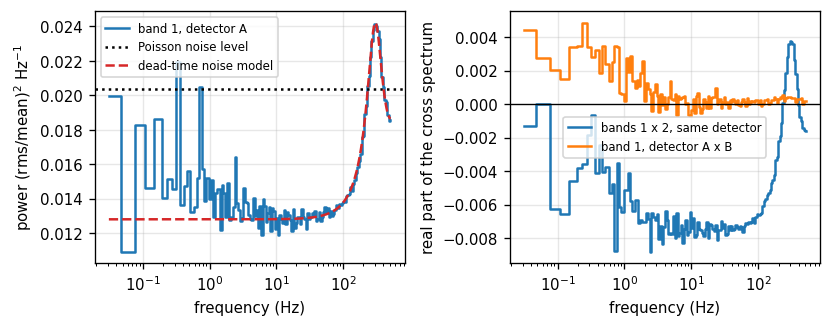

In [23]:
options = dict(segment_size=segment_dt, dt=dt_dt, norm="frac", silent=True)
same_detector = AveragedCrossspectrum(a1, a2, **options)  # band 1 x band 2, detector A
between_detectors = AveragedCrossspectrum(a1, b1, **options)  # band 1, detector A x detector B
same_reb, between_reb = same_detector.rebin_log(0.05), between_detectors.rebin_log(0.05)

# Dead-time noise model of band 1 in detector A. The dead time depends on the photons of both
# bands: band 2 enters as a "background" rate. The model is in Leahy normalization (2 for pure
# Poisson noise); dividing by the mean count rate converts it to fractional rms normalization.
rate1_det, rate2_det = a1.time.size / T_dt, a2.time.size / T_dt
noise_model = non_paralyzable_dead_time_model(
    same_detector.freq, deadtime, rate1_det, bin_time=dt_dt, background_rate=rate2_det
) / rate1_det

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(7, 2.8))
ax0.plot(same_reb.freq, same_reb.pds1.power, drawstyle="steps-mid", label="band 1, detector A")
ax0.axhline(poisson_level("frac", meanrate=rate1_det), color="k", ls=":", label="Poisson noise level")
ax0.plot(same_detector.freq, noise_model, "C3--", label="dead-time noise model")
ax0.set(xscale="log", xlabel="frequency (Hz)", ylabel=r"power (rms/mean)$^2$ Hz$^{-1}$")
ax0.legend(fontsize=7)
ax1.plot(same_reb.freq, same_reb.power.real, drawstyle="steps-mid", label="bands 1 x 2, same detector")
ax1.plot(between_reb.freq, between_reb.power.real, drawstyle="steps-mid", label="band 1, detector A x B")
ax1.axhline(0, color="k", lw=0.8)
ax1.set(xscale="log", xlabel="frequency (Hz)", ylabel="real part of the cross spectrum")
ax1.legend(fontsize=7)
fig.tight_layout()
plt.show()

**What the figure shows.** Left: dead time lowers the noise level to about 0.6 times the Poisson
level below 100 Hz, and makes it rise above the Poisson level (by up to about 20%) near
300 Hz. Stingray's dead-time model follows the measured noise. Its only inputs are the dead time and the
recorded rates of the two bands. At low frequency the power is above the model because of the
source variability. Right: the cross spectrum of the two bands *in the same detector* is
dominated by dead time. It is negative from a few Hz to about 200 Hz, because a photon in one
band blinds the detector to photons of the other band, and it turns positive near 300 Hz. If we
did not know about dead time, we would read this as a large, frequency-dependent anticorrelation
of the source. The cospectrum of the *two detectors* has none of this: it contains only the
source, and goes to zero where the source power does.

Now we compute, in ten frequency windows centred on `np.linspace(0.1, 400, 10)` Hz, these
estimates of the coherence:

* **single detector**: the intrinsic coherence of detector A, with the standard Poisson noise
  levels, as one would do without a second detector;
* **two detectors**: the cross-detector coherence, with its interval calculated in two ways:
  with the same-detector cross spectra $C_A$ and $C_B$, as recommended, and without them, as
  if they were equal to $S_{12}$. The difference is explained after the results.

The window around 0.1 Hz is 0.16 Hz wide (5 frequency bins); the others are 44 Hz wide (1408 bins).

What is the true value? Dead time does not only change the noise: it also mixes the two bands of
the source signal. When the band 1 count rate goes up, the detector is dead more often and
records fewer band 2 photons, so the recorded band 2 light curve contains a small negative copy
of band 1, and vice versa. This changes the coherence of the *recorded* signal, by an amount
that depends on frequency, and no noise treatment can undo it. So we define the truth as the
coherence of the matrix averaged over all the simulated observations: with so many averaged
values, its bias and scatter are negligible. For comparison, we also show the coherence of the
source *before* dead time, calculated from the model spectra.

We simulate 100 observations of 1024 s (this takes about three minutes).

In [24]:
targets = np.linspace(0.1, 400, 10)
half_widths = np.where(targets < 1, 0.08, 22.0)  # half width of each frequency window (Hz)


def window_means(spectrum, freq):
    # Average a spectrum in each frequency window; also return the number of bins in each
    sel = [np.abs(freq - f) <= hw for f, hw in zip(targets, half_widths)]
    return np.array([spectrum[s].mean() for s in sel]), np.array([s.sum() for s in sel])


def analyse_dead_time_observation(a1, a2, b1, b2):
    # Window averages of the cross-detector matrix and of the single-detector spectra
    matrix = cross_detector_spectral_matrix(a1, a2, b1, b2, segment_size=segment_dt, dt=dt_dt)
    single = AveragedCrossspectrum(a1, a2, **options)
    entries = [matrix.power1, matrix.power2, matrix.cross_power, *matrix.auto_powers,
               single.power, single.pds1.power, single.pds2.power, *matrix.same_detector_cross]
    means = [window_means(e, matrix.freq)[0] for e in entries]
    n_bins = window_means(matrix.freq, matrix.freq)[1]
    noise = [poisson_level("frac", meanrate=ev.time.size / T_dt) for ev in (a1, a2)]
    return means, matrix.m * n_bins, noise


n_obs_dt = 100
dt_results = [analyse_dead_time_observation(a1, a2, b1, b2)]  # the observation above
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _ in range(n_obs_dt - 1):
        dt_results.append(analyse_dead_time_observation(*simulate_dead_time_observation()))

means = np.array([r[0] for r in dt_results])  # (n_obs, 10 entries, 10 windows)
s11, s22, s12 = means[:, 0].real, means[:, 1].real, means[:, 2]
auto = [means[:, k].real for k in range(3, 7)]
single_cross, single_p1, single_p2 = means[:, 7], means[:, 8].real, means[:, 9].real
same_cross = (means[:, 10], means[:, 11])  # C_A and C_B, the same-detector cross spectra
n_ave = dt_results[0][1]  # number of averaged values in each window (same for all observations)
noise1, noise2 = np.array([r[2] for r in dt_results]).T  # Poisson noise levels, single detector

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # Truth: the coherence of the matrix averaged over all observations
    true_dt = cross_detector_coherence(
        s11.mean(0), s22.mean(0), s12.mean(0), [p.mean(0) for p in auto], n_ave * n_obs_dt
    )
    # two detectors: interval without and with the same-detector cross spectra
    two_basic = cross_detector_coherence(s11, s22, s12, auto, n_ave, return_interval=True)
    two = cross_detector_coherence(s11, s22, s12, auto, n_ave, return_interval=True,
                                   same_detector_cross=same_cross)
    one = intrinsic_coherence(single_cross, single_p1, single_p2, noise1[:, None], noise2[:, None],
                              n_ave, return_interval=True)

# Coherence of the source before dead time, from the model spectra averaged in each window
sim_freq = np.fft.rfftfreq(n_bins_dt, dt_dt)[1:]
model = {}
for name, (rms, hwhm) in components_dt.items():
    shape = lorentzian(hwhm)
    model[name] = window_means(rms**2 * shape(sim_freq) / (np.sum(shape(sim_freq)) / T_dt), sim_freq)[0]
shared_power = model["A_low"] + model["A_high"]
injected = shared_power**2 / ((shared_power + model["B"]) * (shared_power + model["C"]))

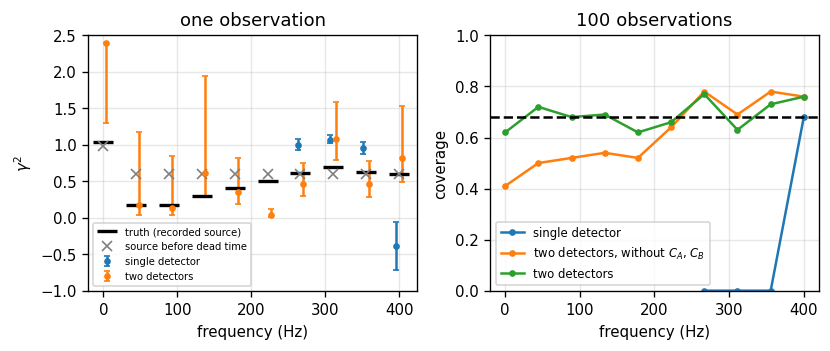

window (Hz) | truth | noise / Poisson | corr(S11, Re S12) | coverage, median width: without C_A C_B | with C_A C_B
        0.1 |  1.04 |            0.63 |             -0.03 |                     0.41, 0.68 |      0.62, 1.00
       44.5 |  0.18 |            0.63 |             -0.70 |                     0.50, 0.47 |      0.72, 0.99
       89.0 |  0.18 |            0.66 |             -0.61 |                     0.52, 0.37 |      0.68, 0.66
      133.4 |  0.29 |            0.71 |             -0.53 |                     0.54, 0.45 |      0.69, 0.73
      177.8 |  0.41 |            0.80 |             -0.48 |                     0.52, 0.48 |      0.62, 0.64
      222.3 |  0.50 |            0.94 |             -0.20 |                     0.64, 0.52 |      0.66, 0.56
      266.7 |  0.62 |            1.10 |             +0.05 |                     0.78, 0.58 |      0.77, 0.52
      311.1 |  0.70 |            1.17 |             +0.22 |                     0.69, 0.68 |      0.63, 0.58
      355.6 |

In [25]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(7, 3))
# Left: the first observation
for (coh, lower, upper), label, shift in ((one, "single detector", -4), (two, "two detectors", 4)):
    ax0.errorbar(targets + shift, coh[0], yerr=[coh[0] - lower[0], upper[0] - coh[0]], fmt="o", ms=3,
                 capsize=2, label=label)
ax0.plot(targets, true_dt, "k_", ms=12, mew=2, label="truth (recorded source)")
ax0.plot(targets, injected, "x", color="grey", label="source before dead time")
ax0.set(xlabel="frequency (Hz)", ylabel=r"$\gamma^2$", ylim=(-1, 2.5), title="one observation")
ax0.legend(fontsize=6)

# Right: coverage in each window, over all observations
for (coh, lower, upper), label in ((one, "single detector"),
                                   (two_basic, r"two detectors, without $C_A$, $C_B$"),
                                   (two, "two detectors")):
    defined = ~np.isnan(lower)
    inside = (lower <= true_dt) & (true_dt <= upper)
    cov = np.array([inside[defined[:, j], j].mean() for j in range(targets.size)])
    ax1.plot(targets, cov, "o-", ms=3, label=label)
ax1.axhline(0.68, color="k", ls="--")
ax1.set(xlabel="frequency (Hz)", ylabel="coverage", ylim=(0, 1), title=f"{n_obs_dt} observations")
ax1.legend(fontsize=7)
fig.tight_layout()
plt.show()

def coverage_and_width(result):
    # coverage and median width of an interval in each window, and all windows together
    coh, lower, upper = result
    defined = ~np.isnan(lower)
    inside = (lower <= true_dt) & (true_dt <= upper)
    per_window = np.array([inside[defined[:, j], j].mean() for j in range(targets.size)])
    return per_window, np.nanmedian(upper - lower, axis=0), inside[defined].mean(), defined


cov_b, width_b, all_b, _ = coverage_and_width(two_basic)
cov_t, width_t, all_t, defined2 = coverage_and_width(two)
print("window (Hz) | truth | noise / Poisson | corr(S11, Re S12) | coverage, median width: "
      "without C_A C_B | with C_A C_B")
for j, f in enumerate(targets):
    ratio = np.mean(auto[0][:, j] - s11[:, j]) / noise1.mean()
    # correlation coefficient of S11 and Re S12 over the observations (zero if independent)
    corr = np.corrcoef(s11[:, j], s12[:, j].real)[0, 1]
    print(f"{f:11.1f} | {true_dt[j]:5.2f} | {ratio:15.2f} | {corr:+17.2f} | "
          f"{cov_b[j]:24.2f}, {width_b[j]:4.2f} | {cov_t[j]:9.2f}, {width_t[j]:4.2f}")
print(f"Undefined two-detector estimates: {1 - defined2.mean():.3f}")
print(f"All windows together: coverage {all_b:.3f} without C_A C_B, {all_t:.3f} with them "
      f"(statistical uncertainty {np.sqrt(0.68 * 0.32 / defined2.sum()):.3f}; "
      f"per window {np.sqrt(0.68 * 0.32 / n_obs_dt):.3f}; correlation coefficients {1 / np.sqrt(n_obs_dt):.2f})")

**How to read this.**

* **Single detector**: with the standard Poisson noise levels, the noise-subtracted powers are
  far off. Below about 250 Hz the true noise is lower than the Poisson level, so the subtraction
  removes too much and the powers become negative: all estimates are undefined. Between 250 and
  360 Hz the true noise is *higher* than the Poisson level, and the estimates are defined but
  wrong (coverage 0). Only at 400 Hz, where the dead-time noise happens to be equal to the Poisson
  level, does the single-detector interval work. This is exactly the problem the two-detector
  method solves.
* **Two detectors**: there are no undefined estimates. With $C_A$ and $C_B$, the coverage is
  close to 0.68 in every window: 0.62-0.77, each value with an uncertainty of about 0.05, and
  0.69 overall. Without them, it is too low below 200 Hz (0.41-0.54: the intervals are too
  narrow, i.e. too optimistic), and fine above 250 Hz.

Why do $C_A$ and $C_B$ matter? Within each detector, dead time correlates the noise of the two
bands (the cross spectrum of the same detector in the figure above, negative up to 200 Hz and
positive near 300 Hz). This correlation cancels in all the entries of the matrix, so the
coherence is not biased, but it correlates the *fluctuations* of $S_{11}$ and $S_{22}$ with
those of $S_{12}$. The fourth column shows the correlation coefficient between $S_{11}$ and
${\rm Re}\,S_{12}$ across the observations (uncertainty about 0.1): down to $-0.70$ at 44 Hz, and up to $+0.27$ at 400 Hz. Without $C_A$
and $C_B$, the variance assumes there is no such correlation. Where the correlation is
negative, the coherence actually scatters *more* than this variance says, and the intervals
are too narrow; where it is positive, the coherence scatters less, and they are too wide. With
$C_A$ and $C_B$, the general variance accounts for the correlation in both cases.

The window at 0.1 Hz is a reminder of the limits of these tests: it contains only 5 frequency
bins times 32 segments, and the coherence there is high, so the coverage is less precise.

### Are the two pairings in $S_{12}$ independent?

We now come back to the question raised at the start of this section. Call the two pairings
$X = A_1^* B_2$ and $Y = B_1^* A_2$, for one segment and one frequency bin. For Gaussian Fourier
amplitudes, the calculation of the averages of products of four amplitudes gives three
predictions:

1. $X$ and $Y$ have the same average, the cross spectrum of the source: averaging them does not
   change what we measure.
2. Their fluctuations are correlated, with covariance
   ${\rm E}[(X - \bar X)(Y - \bar Y)^*] = S_{11} S_{22}$ ("E" is the average over many
   realizations, the bar the mean). This comes from the source signal that both pairings
   contain, and it is the $2 S_{11} S_{22}$ term in $b^2$. It does not involve the noise.
3. There is a second kind of correlation, without the complex conjugate:
   ${\rm E}[(X - \bar X)(Y - \bar Y)] = C_A C_B$, where $C_A = \langle A_1^* A_2\rangle$ and
   $C_B = \langle B_1^* B_2\rangle$ are the cross spectra of the two bands *within* each
   detector. With dead time, these include the anticorrelated noise of the two bands that we saw
   in the figure above. This term does not change the variance of $S_{12}$ (the average of
   $|S_{12} - \bar S_{12}|^2$), so it does not change $b^2$. It changes how this variance is
   shared between the real and the imaginary part of $S_{12}$. A single pairing does not have it.

To test these predictions, we need the Fourier amplitudes of each segment, which
`AveragedCrossspectrum` does not keep. So we compute them directly with NumPy, for one longer
observation (128 segments), and measure the averages above over all segments and frequency bins
in each window. We add a window from 0.05 to 2 Hz, where the source is strong.

In [26]:
def segment_amplitudes(events, dt, segment_size, n_seg):
    # Fourier amplitudes of each segment (rows) at each positive frequency (columns), scaled so
    # that |amplitude|^2 is the power in fractional rms normalization
    n_bin = int(round(segment_size / dt))
    counts = np.histogram(events.time, bins=np.arange(n_seg * n_bin + 1) * dt)[0].reshape(n_seg, n_bin)
    ft = np.fft.rfft(counts, axis=1)[:, 1:]
    return ft * np.sqrt(2 * dt / (n_bin * counts.mean() ** 2))


# One observation of 128 segments, with the same source and detectors as above
n_seg_long = 128
A1, A2, B1, B2 = (
    segment_amplitudes(ev, dt_dt, segment_dt, n_seg_long)
    for ev in simulate_dead_time_observation(n_seg_long)
)
freq_seg = np.fft.rfftfreq(int(segment_dt / dt_dt), dt_dt)[1:]
X, Y = np.conj(A1) * B2, np.conj(B1) * A2  # the two pairings, for each segment and frequency

windows = [(0.05, 2.0)] + [(f - 22, f + 22) for f in targets[1:]]
print(" window (Hz) | (mean X - mean Y)/sigma | (covariance - S11 S22)/sigma | pseudo-cov. / C_A C_B | "
      "correlation coeff.: cov., pseudo-cov.")
for lo, hi in windows:
    sel = (freq_seg >= lo) & (freq_seg <= hi)
    x, y = X[:, sel].ravel(), Y[:, sel].ravel()  # one value per segment and frequency bin
    xd, yd = x - x.mean(), y - y.mean()  # fluctuations
    var_x, var_y = np.mean(np.abs(xd) ** 2), np.mean(np.abs(yd) ** 2)
    s11_w = np.mean(np.conj(A1[:, sel]) * B1[:, sel]).real
    s22_w = np.mean(np.conj(A2[:, sel]) * B2[:, sel]).real
    ca, cb = np.mean(np.conj(A1[:, sel]) * A2[:, sel]), np.mean(np.conj(B1[:, sel]) * B2[:, sel])
    cov = np.mean(xd * np.conj(yd))  # prediction 2: S11 S22
    pseudo = np.mean(xd * yd)  # prediction 3: C_A C_B
    diff = abs(x.mean() - y.mean()) / np.sqrt((var_x + var_y) / x.size)  # prediction 1: ~1 or less
    cov_sigma = np.sqrt(var_x * var_y / x.size)  # approximate uncertainty of the covariance
    print(f"{lo:5.0f} - {hi:3.0f} | {diff:23.1f} | {(cov.real - s11_w * s22_w) / cov_sigma:28.1f} | "
          f"{np.abs(pseudo / (ca * cb)):21.2f} | {np.abs(cov) / np.sqrt(var_x * var_y):12.3f}, "
          f"{np.abs(pseudo) / np.sqrt(var_x * var_y):.3f}")
print(f"(statistical uncertainty of a correlation coefficient: about {1 / np.sqrt(x.size):.3f} "
      f"at high frequencies, {1 / np.sqrt(n_seg_long * np.sum((freq_seg >= 0.05) & (freq_seg <= 2))):.3f} "
      "in the first window)")

 window (Hz) | (mean X - mean Y)/sigma | (covariance - S11 S22)/sigma | pseudo-cov. / C_A C_B | correlation coeff.: cov., pseudo-cov.
    0 -   2 |                     2.2 |                          0.0 |                  1.02 |        0.025, 0.120
   23 -  67 |                     0.8 |                         -1.2 |                  1.00 |        0.003, 0.317
   67 - 111 |                     0.9 |                          1.3 |                  1.00 |        0.003, 0.247
  111 - 155 |                     1.2 |                         -1.5 |                  1.02 |        0.004, 0.151
  156 - 200 |                     0.8 |                          1.1 |                  1.06 |        0.003, 0.057
  200 - 244 |                     1.1 |                          0.1 |                  2.71 |        0.001, 0.007
  245 - 289 |                     1.5 |                         -0.4 |                  1.05 |        0.001, 0.012
  289 - 333 |                     2.2 |                      

**How to read this.** All three predictions hold:

1. the means of $X$ and $Y$ agree within 2.2 standard deviations in every window, and within 1.2
   in seven windows out of ten, as expected from chance;
2. the covariance agrees with $S_{11} S_{22}$ within 2 standard deviations in every window. It
   is important in the strong-source window (correlation coefficient 0.02, i.e. twice its
   uncertainty) and tiny at high frequencies, where the noise dominates (0.001-0.004);
3. the pseudo-covariance agrees with $C_A C_B$, measured from the data. It is large (a
   correlation coefficient up to 0.3 at 23-67 Hz) where dead time makes the bands of a
   detector strongly anticorrelated, and it vanishes near 200 Hz, where that anticorrelation
   crosses zero. Where it is that small, the ratio in the table is noisy (e.g. 68 in the last
   window) and means nothing.

So the two pairings are correlated, but exactly as expected for Gaussian amplitudes. The
correlation that matters for the bias $b^2$ (prediction 2) is already in the formula. The other
one (prediction 3) does not change $b^2$. Averaging the two pairings is then safe. It is
also useful: where the noise dominates, the two pairings are almost independent, so their
average has about half the variance of a single pairing.

This justifies the proposed change to `AveragedCrossspectrum` (or to its use in
`cross_detector_spectral_matrix`). The same-detector cross spectra $C_A$ and $C_B$ also
correlate $S_{12}$ with $S_{11}$ and $S_{22}$, as seen in the coverage test; this would happen
with a single pairing too, and the general variance takes care of it when $C_A$ and $C_B$ are
given.

## 7. Summary and recipe

* The **coherence** $\gamma^2 = |\langle C\rangle|^2 / (\langle P_1\rangle\langle P_2\rangle)$
  measures how much of the variability of one band is predictable from the other.
* With Poisson noise, the estimate needs a **bias correction** $b^2$. Stingray now uses
  $b^2 = P_1 P_2 / m$, from the powers *including* noise, and a small correction $c^2$ in the
  denominator. The older formula of Vaughan & Nowak (1997) is only right when the noise dominates.
* The **error bars** of Vaughan & Nowak are not reliable when the noise is not dominant. Stingray
  now builds a 1-sigma **interval by test inversion**: it collects all the values of the true
  coherence that are compatible with the measurement. It can be asymmetric, it can extend beyond
  [0, 1], and it is wide when the coherence is not measured.
* Its **coverage** is close to 68% in simulations from weak to strong signals and from zero to
  full coherence, and in a **full analysis** of simulated event lists done as in the *Spectral
  Timing* tutorial. Where the source is much weaker than the noise, the interval is conservative
  (too wide), and the estimate is often undefined.
* With **two detectors**, the cross-detector coherence needs no noise level. With 2.5 ms of dead
  time, where the single-detector estimate fails completely, its interval has the right
  coverage from 0.1 to 400 Hz, provided that the cross spectra of the two bands within each
  detector ($C_A$, $C_B$) are passed to it. Without them it is too narrow below ~200 Hz.
* $S_{12}$ averages the two possible pairings of bands and detectors. `AveragedCrossspectrum`
  only calculates one of them, $\langle A_1^* B_2\rangle$. The two pairings are correlated
  exactly as predicted for Gaussian amplitudes, so their average is unbiased and the bias $b^2$
  is right.

```python
# One detector, known noise levels
coh, lower, upper = intrinsic_coherence(cross, power1, power2, noise1, noise2, n_ave, return_interval=True)
# or, from an AveragedCrossspectrum (rebinned or not)
coh, lower, upper = cs.intrinsic_coherence(return_interval=True)

# Two detectors, no noise level
matrix = cross_detector_spectral_matrix(soft_a, hard_a, soft_b, hard_b, segment_size=64.0, dt=dt)
coh, lower, upper = cross_detector_coherence(
    matrix.power1, matrix.power2, matrix.cross_power, matrix.auto_powers, matrix.m, return_interval=True,
    same_detector_cross=matrix.same_detector_cross,  # recommended with dead time
)
```

**References**

* Bachetti, M., et al. 2015, ApJ 800, 109: the cospectrum of two detectors.
* Timmer, J., & Koenig, M. 1995, A&A 300, 707: simulating light curves from a power spectrum.
* Vaughan, B. A., & Nowak, M. A. 1997, ApJ 474, L43: the intrinsic coherence.
* Zhang, W., et al. 1995, ApJ 449, 930: the power spectrum of dead-time-affected data.
* Bendat, J. S., & Piersol, A. G., *Random Data: Analysis and Measurement Procedures*: the error
  on the coherence without noise.